In [51]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

In [13]:
# Load the Breast Cancer Wisconsin Diagnostic dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

In [39]:
X.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [23]:
# Dataset shape
X.shape

(569, 30)

In [25]:
# Feature names
X.columns

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')

In [28]:
# Missig value counts
X.isnull().sum()[X.isnull().sum() > 0]

Series([], dtype: int64)

In [ ]:
# Class distribution
class_counts = y.map(dict(enumerate(data.target_names))).value_counts()
class_counts

"""
malignant = 0: cancerous tumor
benign = 1: non-cancerous tumor
"""

Diagnosis
B            357
M            212
Name: count, dtype: int64

In [32]:
# Create stratified splits: 70% training, 15% validation, and 15% testing; use random_state=42


X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [40]:
# Apply StandardScaler where appropriate. Fit only on training data, then transform validation/test data

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [41]:
from IPython.display import display
import pandas as pd

# Dataset summary
summary = pd.DataFrame(
    {
        "Value": [
            X.shape[0],
            X.shape[1],
            y.name,
            int(X.isna().sum().sum()),
            int(y.isna().sum().sum()),
        ]
    },
    index=[
        "Number of samples",
        "Number of features",
        "Target column",
        "Missing feature values",
        "Missing target values",
    ],
)
display(summary)

,Value
Number of samples,569
Number of features,30
Target column,Diagnosis
Missing feature values,0
Missing target values,0


In [42]:
# Feature and target shapes for each split
split_shapes = pd.DataFrame(
    {
        "Features": [X_train.shape, X_val.shape, X_test.shape],
        "Target": [y_train.shape, y_val.shape, y_test.shape],
    },
    index=["Train", "Validation", "Test"],
)
display(split_shapes)

,Features,Target
Train,"(398, 30)","(398, 1)"
Validation,"(85, 30)","(85, 1)"
Test,"(86, 30)","(86, 1)"


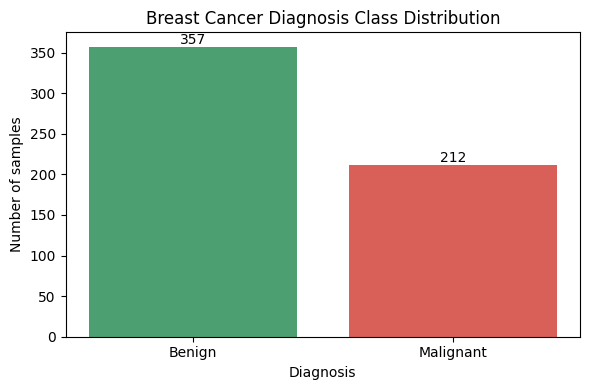

In [43]:
import matplotlib.pyplot as plt

# Class distribution
class_counts = y.map(dict(enumerate(data.target_names))).value_counts().reindex(data.target_names, fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=["#D95F59", "#4C9F70"],
)
ax.bar_label(bars)
ax.set_title("Breast Cancer Diagnosis Class Distribution")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of samples")
fig.tight_layout()
plt.show()

In [44]:
# Task 2: Define the six required model configurations
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from time import perf_counter

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree (Gini)": DecisionTreeClassifier(criterion="gini", random_state=42),
    "Decision Tree (Entropy)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "PCA + KNN": make_pipeline(
        PCA(n_components=0.95),
        KNeighborsClassifier(n_neighbors=5),
    ),
}

# Distance- and scale-sensitive models use standardized data; trees use the original features.
scaled_models = {"Logistic Regression", "KNN", "Gaussian Naive Bayes", "PCA + KNN"}
print(f"Configured {len(models)} models.")

Configured 6 models.


In [45]:
# Train on the training split and generate validation/test predictions
model_predictions = {}
metric_rows = []

for model_name, model in models.items():
    if model_name in scaled_models:
        X_fit, X_validation, X_holdout = X_train_scaled, X_val_scaled, X_test_scaled
    else:
        X_fit, X_validation, X_holdout = X_train, X_val, X_test

    fit_start = perf_counter()
    model.fit(X_fit, y_train)
    train_seconds = perf_counter() - fit_start

    prediction_start = perf_counter()
    test_predictions = model.predict(X_holdout)
    test_prediction_ms = (perf_counter() - prediction_start) * 1000
    validation_predictions = model.predict(X_validation)
    model_predictions[model_name] = {
        "validation": validation_predictions,
        "test": test_predictions,
    }

    metric_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, test_predictions),
            "Precision": precision_score(y_test, test_predictions, average="macro", zero_division=0),
            "Recall": recall_score(y_test, test_predictions, average="macro", zero_division=0),
            "F1": f1_score(y_test, test_predictions, average="macro", zero_division=0),
            "Train (s)": train_seconds,
            "Predict (ms)": test_prediction_ms,
        }
    )

model_comparison = pd.DataFrame(metric_rows).set_index("Model")
pca_components = models["PCA + KNN"].named_steps["pca"].n_components_
print(f"PCA retained {pca_components} of {X.shape[1]} features.")

c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


PCA retained 10 of 30 features.


c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [46]:
# Task 3: Mandatory test-set comparison table
display(model_comparison.round(4))

,Accuracy,Precision,Recall,F1,Train (s),Predict (ms)
Model,,,,,,
Logistic Regression,0.9767,0.9751,0.9751,0.9751,0.1031,0.4628
KNN,0.9651,0.9737,0.9531,0.9619,0.0240,2909.1893
Gaussian Naive Bayes,0.9419,0.9477,0.9282,0.9365,0.0036,1.5298
Decision Tree (Gini),0.9070,0.9005,0.9005,0.9005,0.0155,1.3932
Decision Tree (Entropy),0.9535,0.9655,0.9375,0.9488,0.0139,1.5881
PCA + KNN,0.9535,0.9655,0.9375,0.9488,0.0142,3.2906


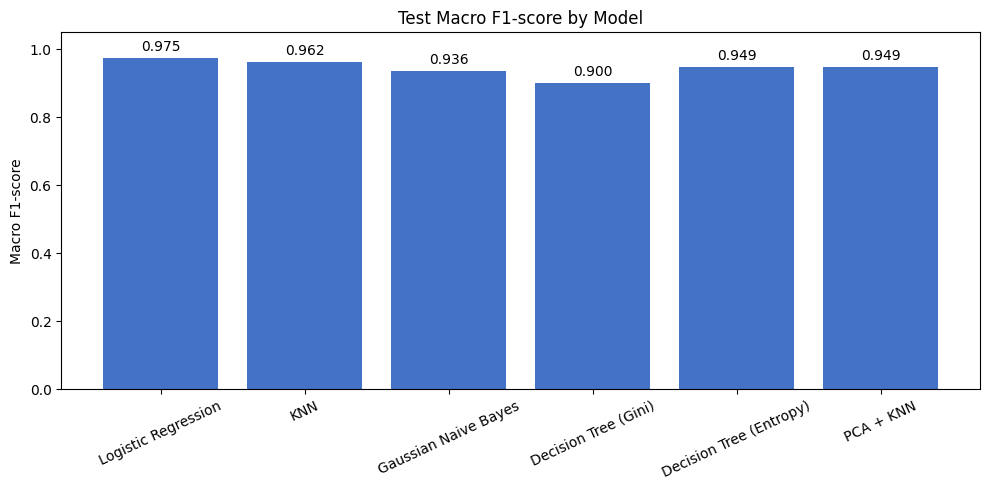

In [47]:
# Compare test macro F1-scores
fig, ax = plt.subplots(figsize=(10, 5))
f1_bars = ax.bar(model_comparison.index, model_comparison["F1"], color="#4472C4")
ax.bar_label(f1_bars, fmt="{:.3f}", padding=3)
ax.set_title("Test Macro F1-score by Model")
ax.set_ylabel("Macro F1-score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

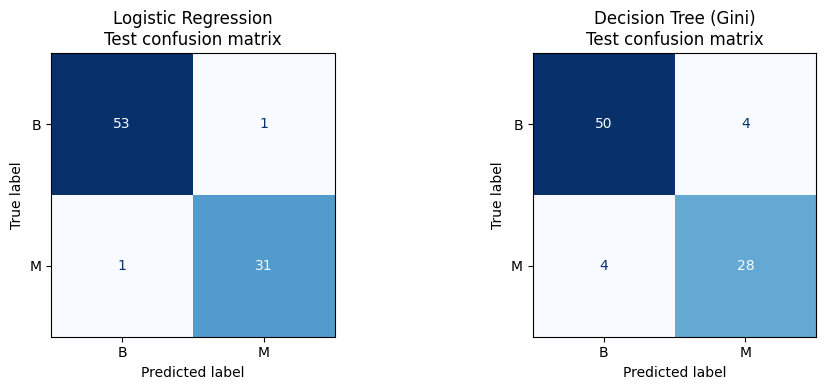

In [48]:
# Confusion matrices for the highest- and lowest-F1 models
highest_f1_model = model_comparison["F1"].idxmax()
lowest_f1_model = model_comparison["F1"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model_name in zip(axes, [highest_f1_model, lowest_f1_model]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model_predictions[model_name]["test"],
        display_labels=data.target_names,
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )
    ax.set_title(f"{model_name}\nTest confusion matrix")
fig.tight_layout()
plt.show()

c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighbors\_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\Adarsh Kumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neighb

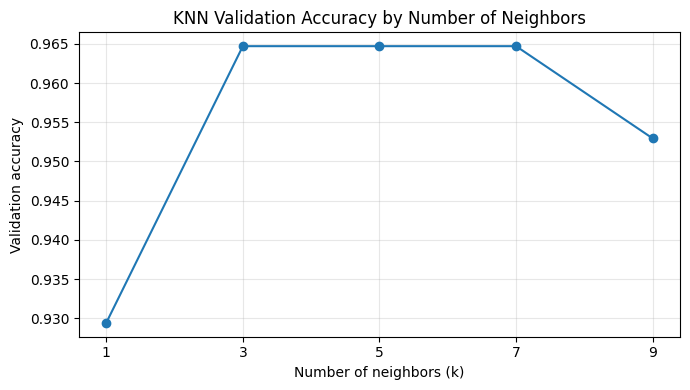

Validation-selected k: 3
Selected KNN test accuracy: 0.9535


In [49]:
# Task 4A: Select K using validation accuracy only, then evaluate the selected K on the test set
k_values = [1, 3, 5, 7, 9]
knn_validation_accuracy = {}

for k in k_values:
    candidate = KNeighborsClassifier(n_neighbors=k)
    candidate.fit(X_train_scaled, y_train)
    validation_predictions = candidate.predict(X_val_scaled)
    knn_validation_accuracy[k] = accuracy_score(y_val, validation_predictions)

best_k = max(k_values, key=knn_validation_accuracy.get)
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
best_knn_test_accuracy = accuracy_score(y_test, best_knn.predict(X_test_scaled))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, [knn_validation_accuracy[k] for k in k_values], marker="o")
ax.set_xticks(k_values)
ax.set_title("KNN Validation Accuracy by Number of Neighbors")
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Validation accuracy")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Validation-selected k: {best_k}")
print(f"Selected KNN test accuracy: {best_knn_test_accuracy:.4f}")

In [50]:
# Task 4B: Evidence-based short answers
highest_f1_model = model_comparison["F1"].idxmax()
fastest_prediction_model = model_comparison["Predict (ms)"].idxmin()
knn_f1 = model_comparison.loc["KNN", "F1"]
pca_knn_f1 = model_comparison.loc["PCA + KNN", "F1"]
knn_prediction_ms = model_comparison.loc["KNN", "Predict (ms)"]
pca_knn_prediction_ms = model_comparison.loc["PCA + KNN", "Predict (ms)"]
gini_predictions = model_predictions["Decision Tree (Gini)"]["test"]
entropy_predictions = model_predictions["Decision Tree (Entropy)"]["test"]
trees_identical = (gini_predictions == entropy_predictions).all()
selected_model = highest_f1_model

print(
    f"1. Highest test macro F1: {highest_f1_model} "
    f"({model_comparison.loc[highest_f1_model, 'F1']:.4f}). "
    f"Fastest test prediction: {fastest_prediction_model} "
    f"({model_comparison.loc[fastest_prediction_model, 'Predict (ms)']:.3f} ms); "
    f"the highest-F1 model is {'also ' if highest_f1_model == fastest_prediction_model else 'not '}the fastest by measured prediction time."
)
print(
    f"2. PCA retained {pca_components}/{X.shape[1]} components. "
    f"Compared with ordinary KNN, PCA + KNN test macro F1 changed from {knn_f1:.4f} to {pca_knn_f1:.4f}, "
    f"and prediction time changed from {knn_prediction_ms:.3f} ms to {pca_knn_prediction_ms:.3f} ms."
)
print(
    f"3. Gini and entropy trees {'produced identical test predictions' if trees_identical else 'produced different test predictions'} "
    f"(Gini F1={model_comparison.loc['Decision Tree (Gini)', 'F1']:.4f}; "
    f"Entropy F1={model_comparison.loc['Decision Tree (Entropy)', 'F1']:.4f}). "
    "They optimize different split-impurity criteria, so identical outcomes are not guaranteed."
)
print(
    "4. Scaling matters for KNN because distances otherwise depend on feature units, and for Logistic Regression "
    "because it improves numerical conditioning and makes regularization act comparably across features. "
    "Decision Trees split one feature at a time using thresholds, so rescaling a feature generally preserves the available partitions."
)
print(
    f"5. Based on this run, I would select {selected_model}: it has the highest held-out macro F1 "
    f"({model_comparison.loc[selected_model, 'F1']:.4f}), with {model_comparison.loc[selected_model, 'Train (s)']:.4f} s training "
    f"and {model_comparison.loc[selected_model, 'Predict (ms)']:.3f} ms test prediction time. "
    "This favors balanced predictive quality while reporting the measured speed trade-off."
)

1. Highest test macro F1: Logistic Regression (0.9751). Fastest test prediction: Logistic Regression (0.463 ms); the highest-F1 model is also the fastest by measured prediction time.
2. PCA retained 10/30 components. Compared with ordinary KNN, PCA + KNN test macro F1 changed from 0.9619 to 0.9488, and prediction time changed from 2909.189 ms to 3.291 ms.
3. Gini and entropy trees produced different test predictions (Gini F1=0.9005; Entropy F1=0.9488). They optimize different split-impurity criteria, so identical outcomes are not guaranteed.
4. Scaling matters for KNN because distances otherwise depend on feature units, and for Logistic Regression because it improves numerical conditioning and makes regularization act comparably across features. Decision Trees split one feature at a time using thresholds, so rescaling a feature generally preserves the available partitions.
5. Based on this run, I would select Logistic Regression: it has the highest held-out macro F1 (0.9751), with 0.10